# Head CT Scan Classifier (PyTorch)

Binary image classifier that predicts whether a head CT scan shows an **infection (1)** or is **healthy (0)**, built from scratch in PyTorch.

*Course context: Machine Learning programming assignment (PA3), LUMS. The assignment framed the task as a sci-fi story: detecting "Code Rot" in humanoid "Guardians" from their CT scans. Underneath, it is a standard binary classification problem on real head CT images.*

## Problem
- **Data:** 8,580 grayscale head CT slices (64×64 JPEGs) and a CSV (`labels.csv`) with an `infected` label (`yes` / `no`) for each file.
- **Task:** train a neural network to classify each scan as healthy or infected, then evaluate it with accuracy, a classification report, a confusion matrix and an ROC curve.
- **Framework:** PyTorch.

## Imports

In [ ]:
# Uncomment if torch/torchvision are not installed
# !pip install torch torchvision

In [ ]:
import numpy as np
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import pandas as pd
import os
import torch.nn as nn
import torch.optim as optim
import torch
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import seaborn as sns
import matplotlib.pyplot as plt
from math import ceil
from torch.utils.data import Subset
import random
from sklearn.model_selection import train_test_split



seed = 42   # for reproducibility
np.random.seed(seed)
random.seed(seed)
torch.manual_seed(seed)


## Loading Data
Load the images, labels and preprocess as necessary.

In [ ]:
# Resize to 128x128, convert to 1 channel, scale to [-1, 1] (normalisation done once, up front)
data_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.Grayscale(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

data_labels = pd.read_csv('data/labels.csv')

image_list = []
label_list = []

for idx in range(len(data_labels)):
    file_path = f"data/HeadCT/{data_labels.loc[idx, 'filename']}"
    raw_image = Image.open(file_path)
    processed_image = data_transform(raw_image)
    
    infection_status = 1 if data_labels.loc[idx, 'infected'] == "yes" else 0
    
    image_list.append(processed_image)
    label_list.append(infection_status)

tensor_images = torch.stack(image_list)
tensor_labels = torch.tensor(label_list)

final_dataset = list(zip(tensor_images, tensor_labels))


## Visualizing Data
- Make a function to plot a set of random images with class labels
- Plot the class distribution

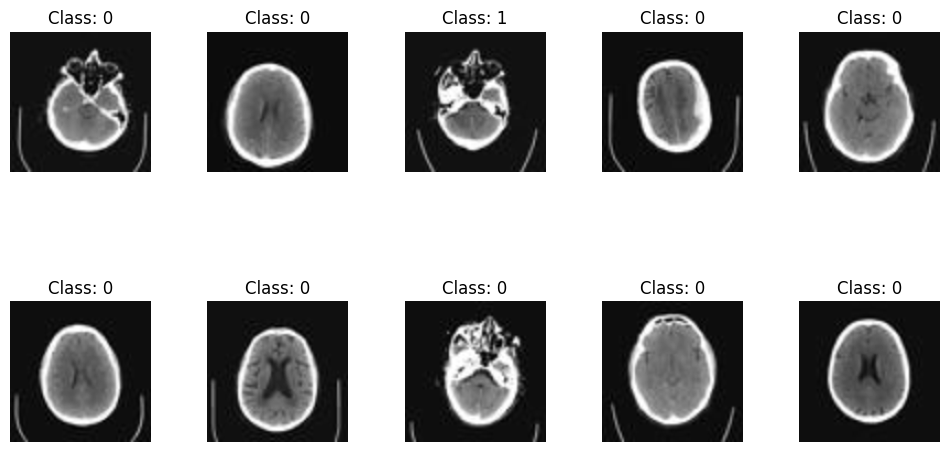

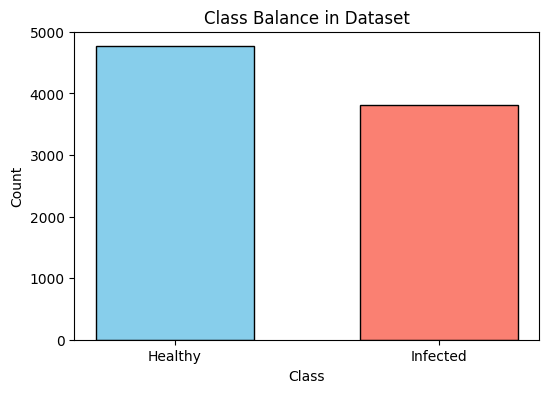

In [ ]:
selected_indices = random.sample(range(len(final_dataset)), 10)
figure, axes_grid = plt.subplots(2, 5, figsize=(12, 6))

for idx, index in enumerate(selected_indices):
    img, lbl = final_dataset[index]
    row_idx = idx // 5
    col_idx = idx % 5
    axis = axes_grid[row_idx, col_idx]
    axis.imshow(img.squeeze().numpy(), cmap='gray')
    axis.set_title(f"Class: {lbl}")
    axis.axis('off')

plt.subplots_adjust(wspace=0.4, hspace=0.4)
plt.show()

label_list = [lbl for _, lbl in final_dataset]
class_counts = [label_list.count(0), label_list.count(1)]
bar_colors = ['skyblue', 'salmon'] 

plt.figure(figsize=(6, 4))
bars = plt.bar([0, 1], class_counts, color=bar_colors, edgecolor="black", width=0.6)
plt.xticks([0, 1], ["Healthy", "Infected"])
plt.title("Class Balance in Dataset")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()


## Train/test split and Normalization
- Perform train, test, val split of a suitable ratio
- Implement a suitable scaler class to normalize the data

In [ ]:
full_indices = list(range(len(final_dataset)))
train_indices, val_indices = train_test_split(full_indices, test_size=0.2, random_state=42)
train_indices, test_indices = train_test_split(train_indices, test_size=0.25, random_state=42)
# 60% train / 20% validation / 20% test, served in mini-batches
batch_size = 32
training_loader = DataLoader(Subset(final_dataset, train_indices), batch_size=batch_size, shuffle=True)
validation_loader = DataLoader(Subset(final_dataset, val_indices), batch_size=batch_size, shuffle=False)
testing_loader = DataLoader(Subset(final_dataset, test_indices), batch_size=batch_size, shuffle=False)


## Create a BinaryClassifier class
- Define a model class, initialize layers with activations as required
- Define a suitable loss function and learning rate

In [ ]:
class BinaryClassifier(nn.Module):
    def __init__(self, input_dims):
        super().__init__()
        self.input_dims = input_dims
        self.fcl1 = nn.Linear(input_dims, 512)
        self.fcl2 = nn.Linear(512, 256)
        self.fcl3 = nn.Linear(256, 128)
        self.fcl4 = nn.Linear(128, 64)
        self.fcl5 = nn.Linear(64, 1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.batch_norm = nn.BatchNorm1d(512)

    def forward(self, x):
        x = x.view(x.size(0), -1)          # flatten 128x128 image -> 16,384 features
        x = self.relu(self.fcl1(x))
        x = self.batch_norm(x)
        x = self.dropout(x)
        x = self.relu(self.fcl2(x))
        x = self.relu(self.fcl3(x))
        x = self.relu(self.fcl4(x))
        x = self.fcl5(x)
        x = torch.sigmoid(x)               # probability of infection
        return x


input_dims = 128 * 128
model = BinaryClassifier(input_dims=input_dims)
print(model)
loss_function = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)


BinaryClassifier(
  (fcl1): Linear(in_features=16384, out_features=512, bias=True)
  (fcl2): Linear(in_features=512, out_features=256, bias=True)
  (fcl3): Linear(in_features=256, out_features=128, bias=True)
  (fcl4): Linear(in_features=128, out_features=64, bias=True)
  (fcl5): Linear(in_features=64, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (batch_norm): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)


## Training Loop
1. **`fit_one_epoch`**: Performs one epoch of training
  
2. **`evaluate`**: Evaluates the model on the validation set.
 
3. **`fit`**: Run all epochs, recording training and validation accuracies and losses

In [ ]:
def fit_one_epoch(model, dataloader, optimizer, loss_fn):
    model.train()
    total_loss = 0
    total_batches = 0
    epoch_accuracy = 0

    for batch in dataloader:
        inputs, targets = batch
        predictions = model(inputs)

        loss = loss_fn(predictions.squeeze(), targets.float())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        batch_predictions = torch.round(predictions.squeeze())
        batch_accuracy = (batch_predictions == targets).float().mean().item() * 100
        epoch_accuracy += batch_accuracy
        total_batches += 1

    average_loss = total_loss / total_batches
    average_accuracy = epoch_accuracy / total_batches
    return average_loss, average_accuracy


@torch.no_grad()
def evaluate(model, dataloader, loss_fn):
    model.eval()
    total_loss = 0
    total_batches = 0
    epoch_accuracy = 0

    for batch in dataloader:
        inputs, targets = batch
        predictions = model(inputs)

        loss = loss_fn(predictions.squeeze(), targets.float())
        total_loss += loss.item()
        batch_predictions = torch.round(predictions.squeeze())
        batch_accuracy = (batch_predictions == targets).float().mean().item() * 100
        epoch_accuracy += batch_accuracy
        total_batches += 1

    average_loss = total_loss / total_batches
    average_accuracy = epoch_accuracy / total_batches
    return average_loss, average_accuracy


train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []


def fit(model, train_dataloader, val_dataloader, optimizer, loss_fn, epochs=150):
    for epoch in range(1, epochs + 1):
        print(f"Epoch {epoch}/{epochs}:")

        train_loss, train_accuracy = fit_one_epoch(model, train_dataloader, optimizer, loss_fn)
        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)

        val_loss, val_accuracy = evaluate(model, val_dataloader, loss_fn)
        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%")
        print(f"Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.2f}%")


In [ ]:
fit(model, training_loader, validation_loader, optimizer, loss_function, epochs=100)

Epoch 1/100:
Train Loss: 0.0118, Train Accuracy: 99.59%
Validation Loss: 0.2023, Validation Accuracy: 96.99%
Epoch 2/100:
Train Loss: 0.0226, Train Accuracy: 99.34%
Validation Loss: 0.2079, Validation Accuracy: 97.22%
Epoch 3/100:
Train Loss: 0.0125, Train Accuracy: 99.59%
Validation Loss: 0.2057, Validation Accuracy: 96.70%
Epoch 4/100:
Train Loss: 0.0111, Train Accuracy: 99.67%
Validation Loss: 0.3998, Validation Accuracy: 96.82%
Epoch 5/100:
Train Loss: 0.0092, Train Accuracy: 99.67%
Validation Loss: 0.2106, Validation Accuracy: 97.05%
Epoch 6/100:
Train Loss: 0.0142, Train Accuracy: 99.55%
Validation Loss: 0.2060, Validation Accuracy: 97.16%
Epoch 7/100:
Train Loss: 0.0147, Train Accuracy: 99.53%
Validation Loss: 0.3004, Validation Accuracy: 95.78%
Epoch 8/100:
Train Loss: 0.0148, Train Accuracy: 99.53%
Validation Loss: 0.1746, Validation Accuracy: 97.16%
Epoch 9/100:
Train Loss: 0.0110, Train Accuracy: 99.65%
Validation Loss: 0.1646, Validation Accuracy: 97.40%
Epoch 10/100:
Train

## Plot Accuracy and Loss Curves

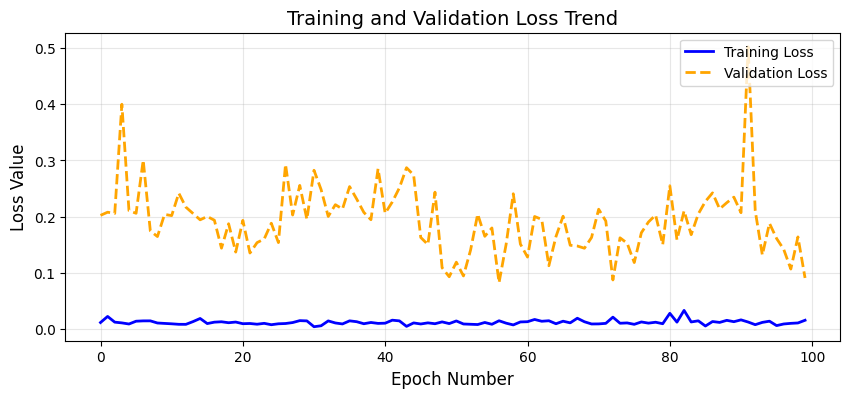

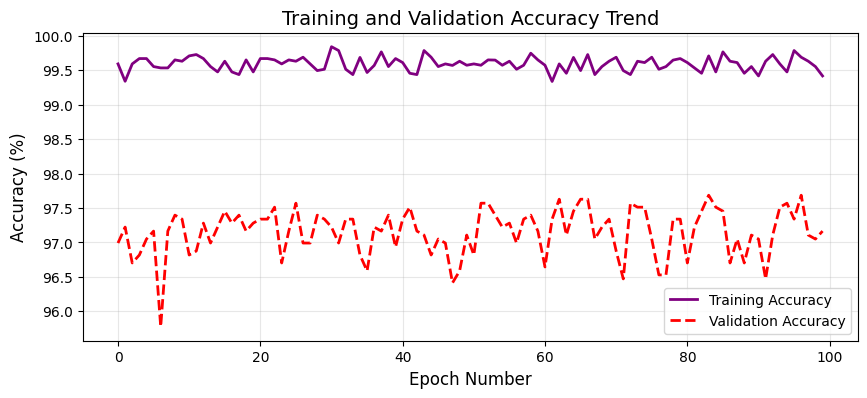

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(range(len(train_losses)), train_losses, label="Training Loss", linestyle="-", linewidth=2, color="blue")
ax1.plot(range(len(val_losses)), val_losses, label="Validation Loss", linestyle="--", linewidth=2, color="orange")
ax1.set_title("Training and Validation Loss Trend", fontsize=14)
ax1.set_xlabel("Epoch Number", fontsize=12)
ax1.set_ylabel("Loss Value", fontsize=12)
ax1.legend(loc="upper right", fontsize=10)
plt.grid(alpha=0.3)
plt.show()

fig, ax2 = plt.subplots(figsize=(10, 4))
ax2.plot(range(len(train_accuracies)), train_accuracies, label="Training Accuracy", linestyle="-", linewidth=2, color="purple")
ax2.plot(range(len(val_accuracies)), val_accuracies, label="Validation Accuracy", linestyle="--", linewidth=2, color="red")
ax2.set_title("Training and Validation Accuracy Trend", fontsize=14)
ax2.set_xlabel("Epoch Number", fontsize=12)
ax2.set_ylabel("Accuracy (%)", fontsize=12)
ax2.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)
plt.show()


## Evaluate on the test set

In [ ]:

loss, accuracy = evaluate(model, testing_loader, loss_function)

print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.2f}%")

Test Loss: 0.1271
Test Accuracy: 97.86%


## Evaluation Metrics
- Classification Report
- Confusion Matrix
- ROC Curve

Evaluation Results:
              precision    recall  f1-score   support

     Class 0       0.98      0.98      0.98       974
     Class 1       0.98      0.97      0.97       742

    accuracy                           0.98      1716
   macro avg       0.98      0.98      0.98      1716
weighted avg       0.98      0.98      0.98      1716



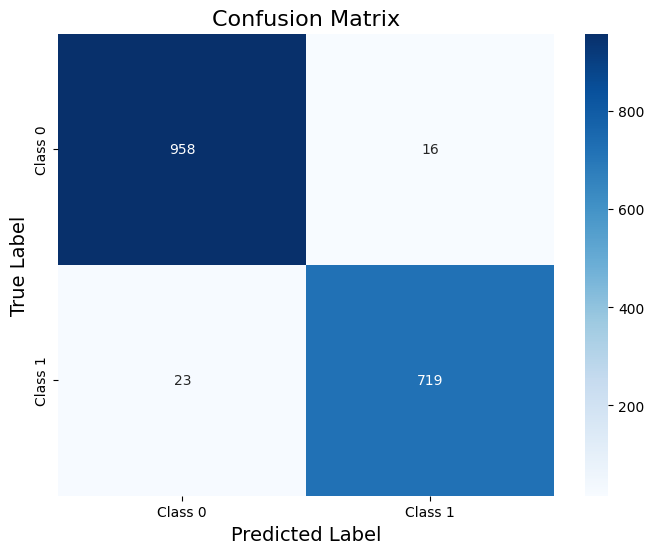

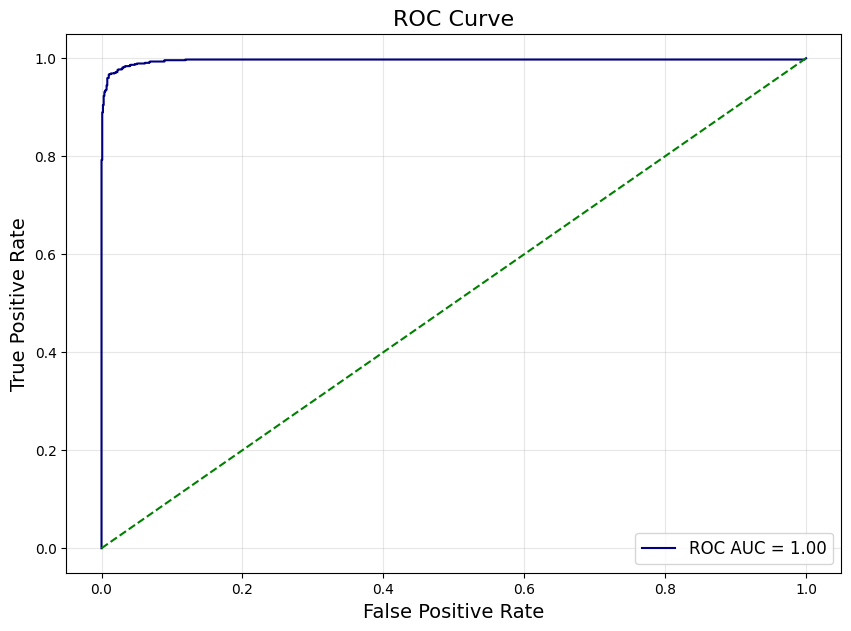

In [ ]:
model.eval()

actual_labels = []
predicted_classes = []
predicted_probs = []

for batch in testing_loader:
    data, labels = batch
    with torch.no_grad():
        logits = model(data)
        binary_preds = (logits > 0.5).float()
        actual_labels.extend(labels.cpu().tolist())
        predicted_classes.extend(binary_preds.cpu().tolist())
        predicted_probs.extend(logits.cpu().squeeze().tolist())

print("Evaluation Results:")
report = classification_report(actual_labels, predicted_classes, target_names=['Class 0', 'Class 1'])
print(report)

conf_matrix = confusion_matrix(actual_labels, predicted_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
plt.title("Confusion Matrix", fontsize=16)
plt.xlabel("Predicted Label", fontsize=14)
plt.ylabel("True Label", fontsize=14)
plt.show()

fpr, tpr, thresholds = roc_curve(actual_labels, predicted_probs)
roc_area = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(fpr, tpr, label=f'ROC AUC = {roc_area:.2f}', color='navy')
ax.plot([0, 1], [0, 1], linestyle='--', color='green')
ax.set_title("ROC Curve", fontsize=16)
ax.set_xlabel("False Positive Rate", fontsize=14)
ax.set_ylabel("True Positive Rate", fontsize=14)
ax.legend(loc="lower right", fontsize=12)
plt.grid(alpha=0.3)
plt.show()


## Where did it go wrong?
Plot images that were missclassified by the model to see where it struggled to differentiate between the classes

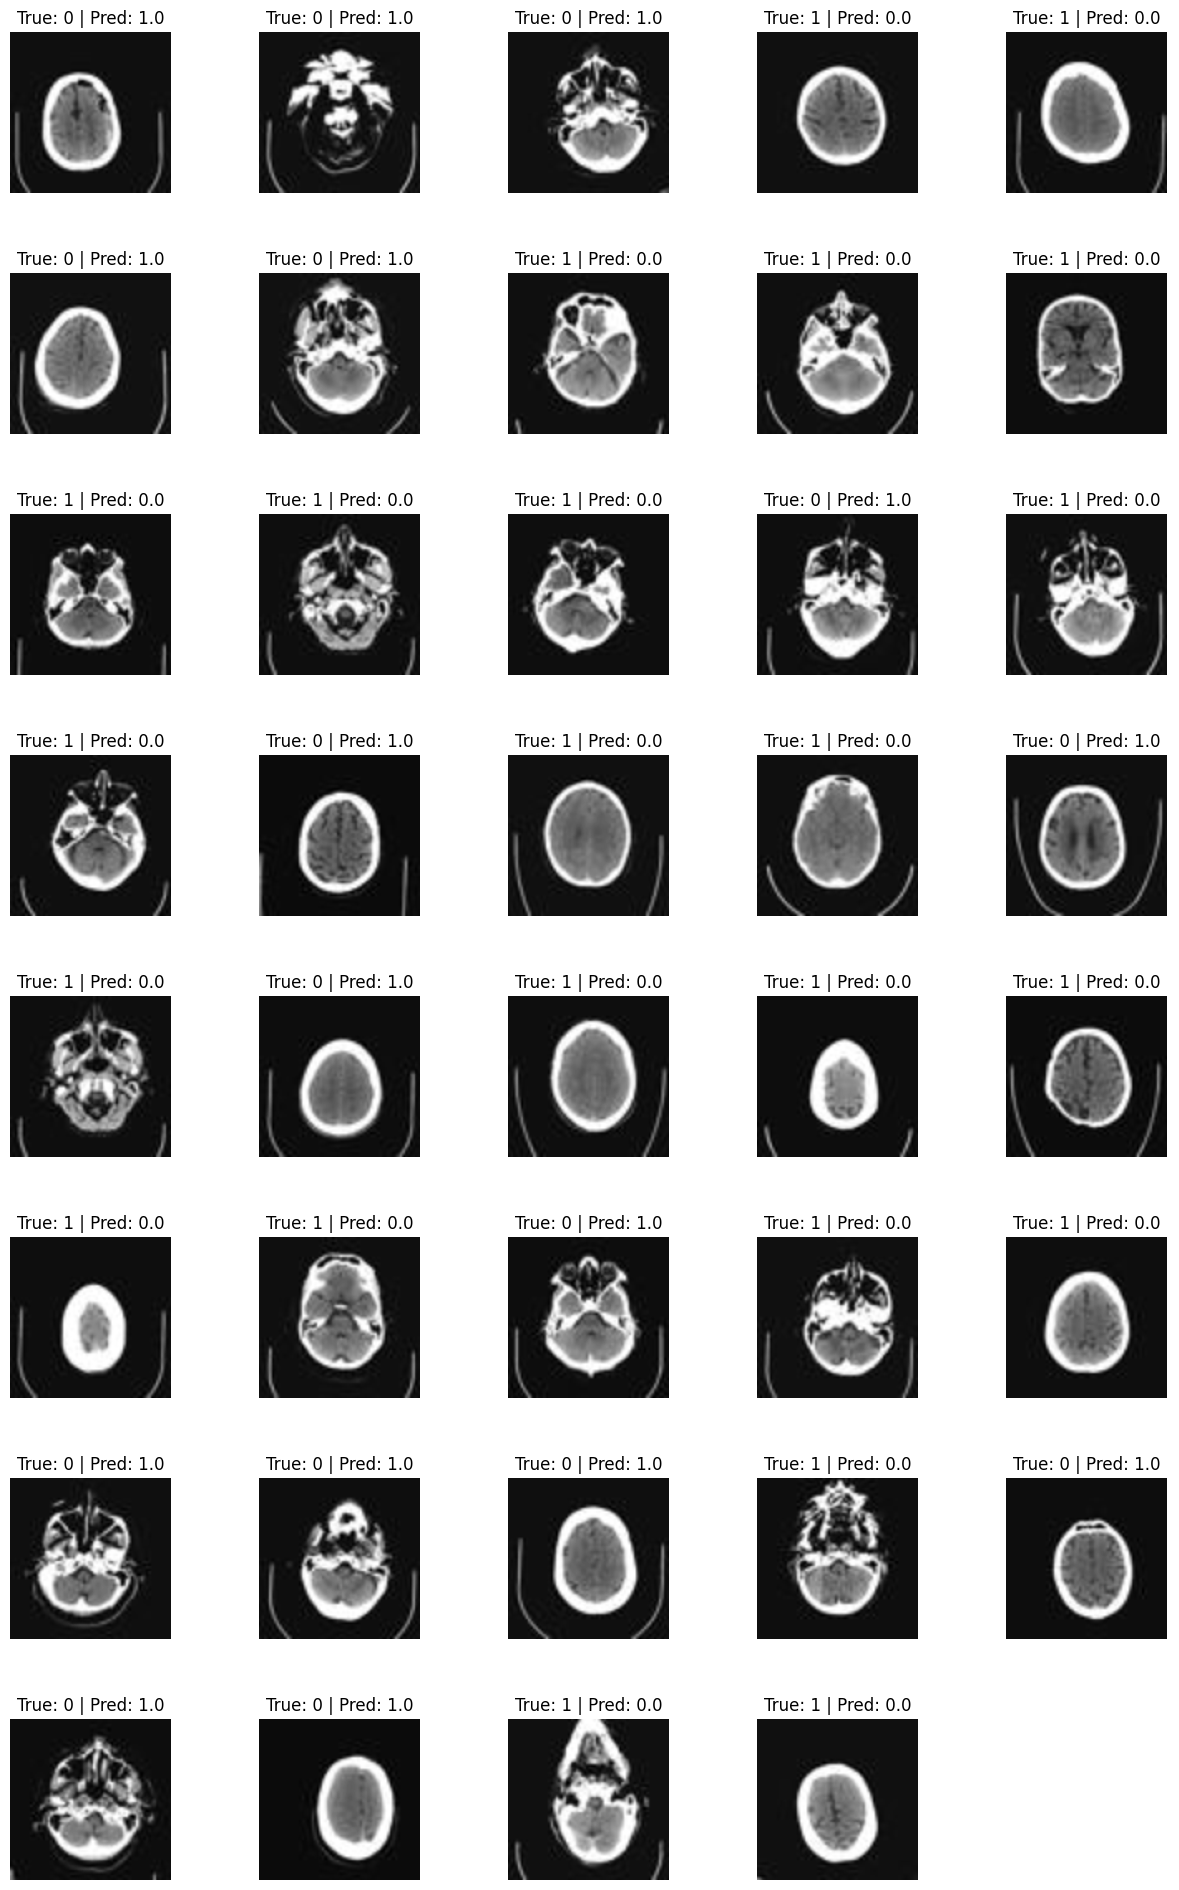

In [ ]:
error_images = []
actual_labels = []
predicted_values = []

model.eval()

batch_iterator = iter(testing_loader)
while True:
    try:
        inputs, targets = next(batch_iterator) 
        with torch.no_grad():
            outputs = model(inputs)  
            predictions = (outputs > 0.5).float().squeeze(1) 
            for img, actual, pred in zip(inputs, targets, predictions):
                if pred != actual:
                    error_images.append(img)  
                    actual_labels.append(actual.item())  
                    predicted_values.append(pred.item())  
    except StopIteration:  
        break

total_errors = len(error_images)
cols = 5
rows = ceil(total_errors / cols)

figure, axes_grid = plt.subplots(rows, cols, figsize=(15, rows * 3))
axes_grid = axes_grid.flatten()

for idx, ax in enumerate(axes_grid):
    if idx < total_errors:
        img = error_images[idx].squeeze().cpu().numpy()
        ax.imshow(img, cmap='gray')
        ax.set_title(f"True: {actual_labels[idx]} | Pred: {predicted_values[idx]}")
        ax.axis('off')
    else:
        ax.axis('off')

plt.subplots_adjust(wspace=0.5, hspace=0.5)
plt.show()


## Summary
- A fully connected network (16,384 → 512 → 256 → 128 → 64 → 1, with batch norm and dropout) reaches **~97.8% test accuracy** and **ROC AUC ≈ 1.00**.
- On the 1,716 test scans: 958 true negatives, 719 true positives, **16 false positives** and **23 false negatives**. Recall on infected scans is 97%.
- Training accuracy stays ~99.5% while validation loss is noisy, a sign of some **overfitting**.
- Many misclassified scans are slices near the **skull base** (sinuses and bone) or the **top of the head**, where there is little brain tissue to look at.
- **Next steps:** a small CNN (convolutions keep the 2D structure that flattening throws away), data augmentation, early stopping on validation loss, and a patient-level split if patient IDs are available.